In [1]:
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
PRT_ALL = sc.read('../SAHAMaxFuse/SAHA_All_PRT_share.h5ad')

In [3]:
adata = sc.read('PRT_COL_SM.h5ad')
adata.obs['phenotype'] = adata.obs['phenotype'].str.replace('likely-', '').astype('category')
adata

PRT = sc.read('../SAHAMaxFuse/PRT_COL.h5ad')

PRT.obs['phenotype'] = adata.obs['phenotype'].astype('category')

In [4]:
# Define your mapping from fine to broad phenotype
phenotype_mapping = {
    'Stroma': 'Mesenchymal-Stromal',
    'Fibroblasts': 'Mesenchymal-Stromal',
    'Endothelial': 'Endothelial',
    'Epithelial': 'Epithelial',
    'Myeloid': 'Myeloid',
    'Macrophages': 'Myeloid',
    'M1 Macrophages': 'Myeloid',
    'M2 Macrophages': 'Myeloid',
    'Monocytes': 'Myeloid',
    'Neutrophils': 'Myeloid',
    'Immune': 'Lymphoid-Other',
    'Dendritic Cells': 'Lymphoid-DC',
    'pDCs': 'Lymphoid-DC',
    'T Cells': 'Lymphoid-T',
    'CD4+ T Cells': 'Lymphoid-T',
    'CD8+ T Cells': 'Lymphoid-T',
    'Tregs': 'Lymphoid-T',
    'Naive T Cells': 'Lymphoid-T',
    'Effector Memory T Cells': 'Lymphoid-T',
    'Exhausted T Cells': 'Lymphoid-T',
    'Tfh Cells': 'Lymphoid-T',
    'CD8+ Cytotoxic': 'Lymphoid-T',
    'NK Cells': 'Lymphoid-T',
    'B Cells': 'Lymphoid-B',
    'Plasma Cells': 'Lymphoid-Plasma',
}

# Apply the mapping
PRT.obs['phenotype_broad'] = PRT.obs['phenotype'].map(phenotype_mapping)

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


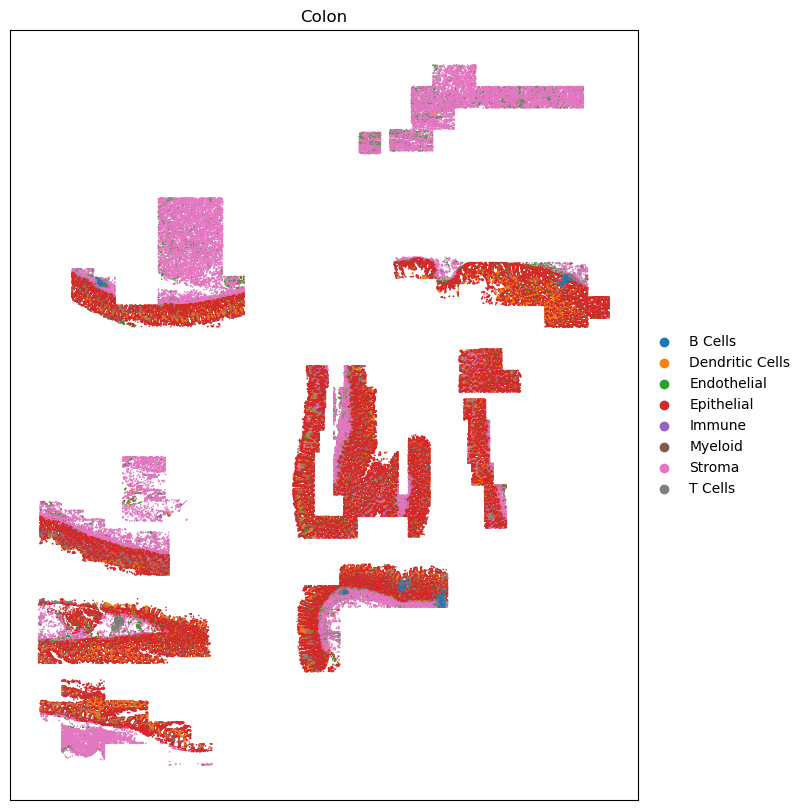

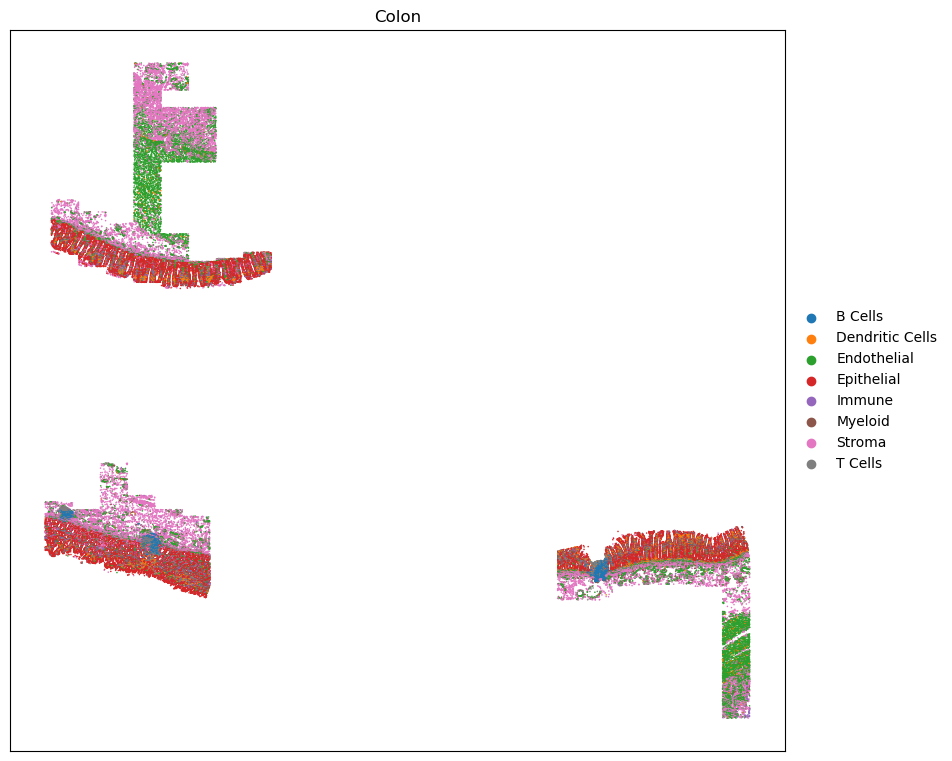

In [5]:
for name in adata.obs['SAHA_name'].unique():
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    sc.pl.embedding(adata[adata.obs['SAHA_name']==name], "spatial", color='phenotype', ax=ax, s=5, show=False)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_aspect('equal')
    ax.set_facecolor('white')
    ax.set_title('Colon')

/tmp/ipykernel_401979/3221162840.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fov_avg_positions = PRT.obs.groupby('fov')[['CenterX_global_px', 'CenterY_global_px']].mean()


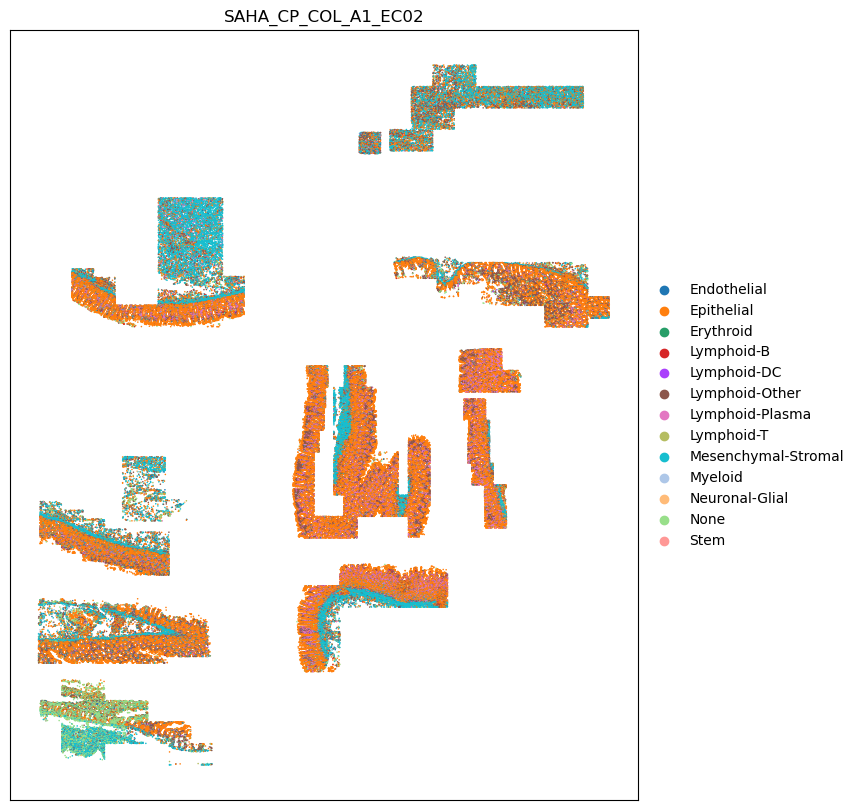

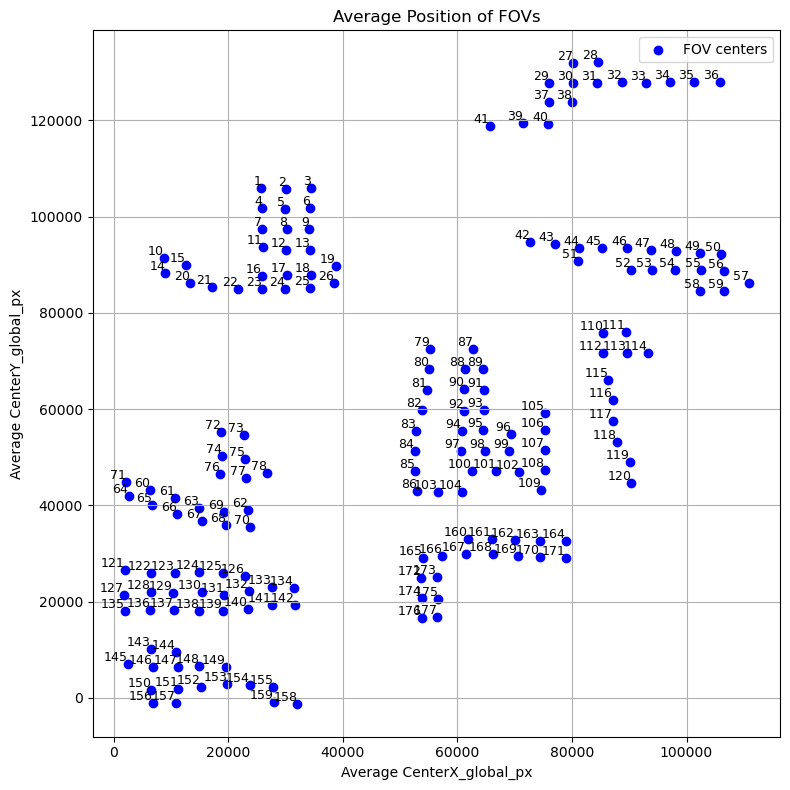

In [6]:
# Colon
PRT_name = 'SAHA_CP_COL_A1_EC02'
PRT = PRT[PRT.obs['SAHA_name']==PRT_name].copy()

PRT.obs['fov'] = PRT_ALL[PRT_ALL.obs['SAHA_name']==PRT_name].obs['fov']

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
sc.pl.embedding(PRT, "spatial", color='celltype_mf', ax=ax, s=5, show=False)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_aspect('equal')
ax.set_facecolor('white')
ax.set_title(PRT_name)

fov_avg_positions = PRT.obs.groupby('fov')[['CenterX_global_px', 'CenterY_global_px']].mean()

# Plotting
plt.figure(figsize=(8, 8))
plt.scatter(fov_avg_positions['CenterX_global_px'], fov_avg_positions['CenterY_global_px'], c='blue', label='FOV centers')

# Label each point with its FOV number
for fov, (x, y) in fov_avg_positions.iterrows():
    plt.text(x, y, str(fov), fontsize=9, ha='right', va='bottom')

# Adding labels and title
plt.xlabel('Average CenterX_global_px')
plt.ylabel('Average CenterY_global_px')
plt.title('Average Position of FOVs')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


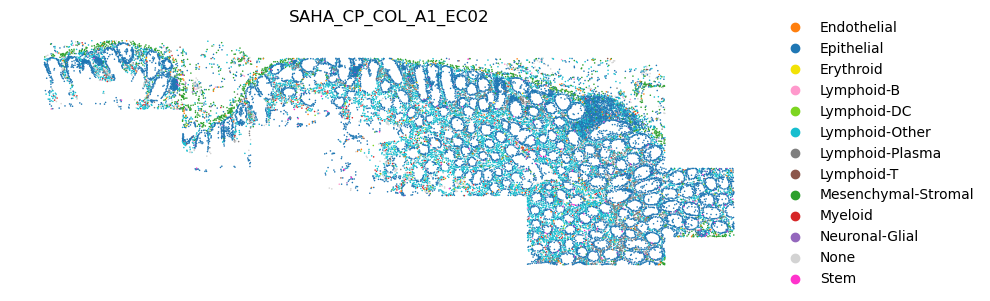

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


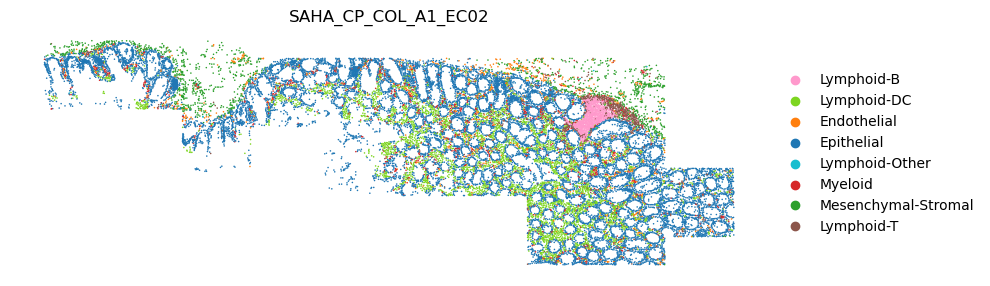

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


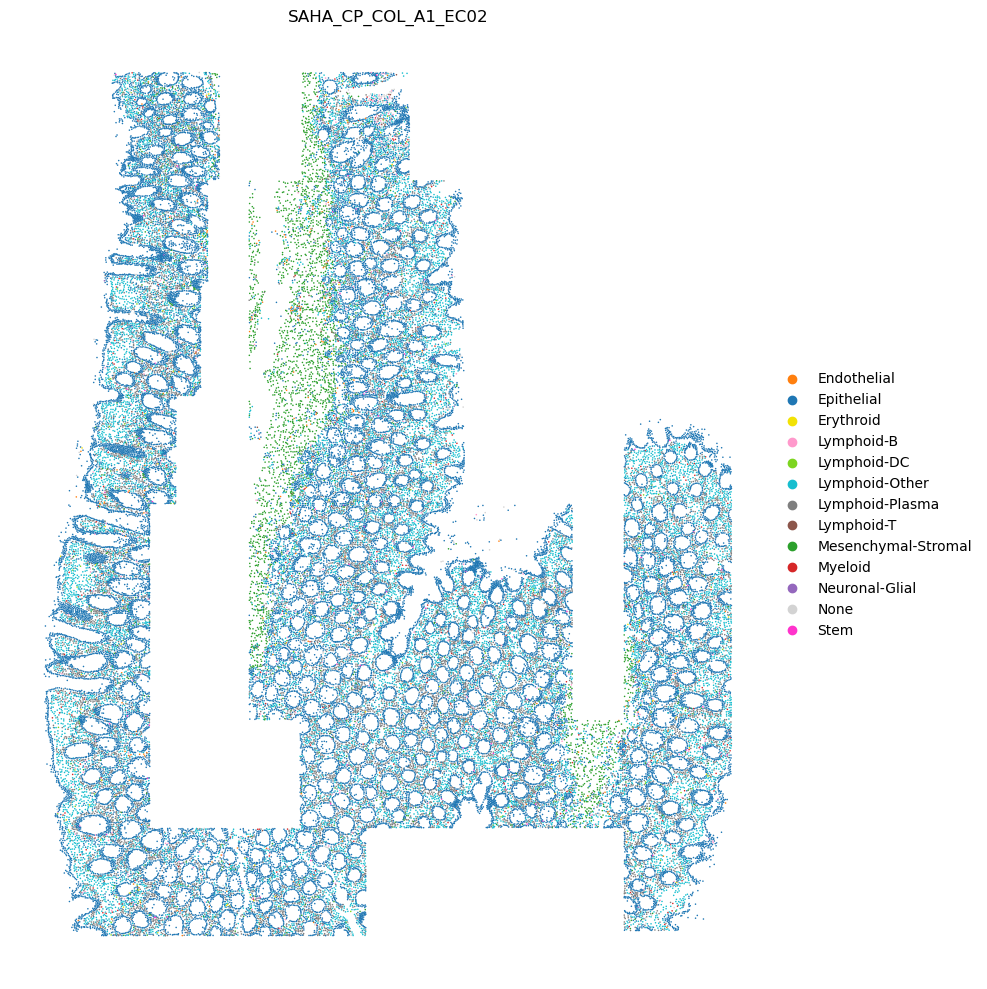

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


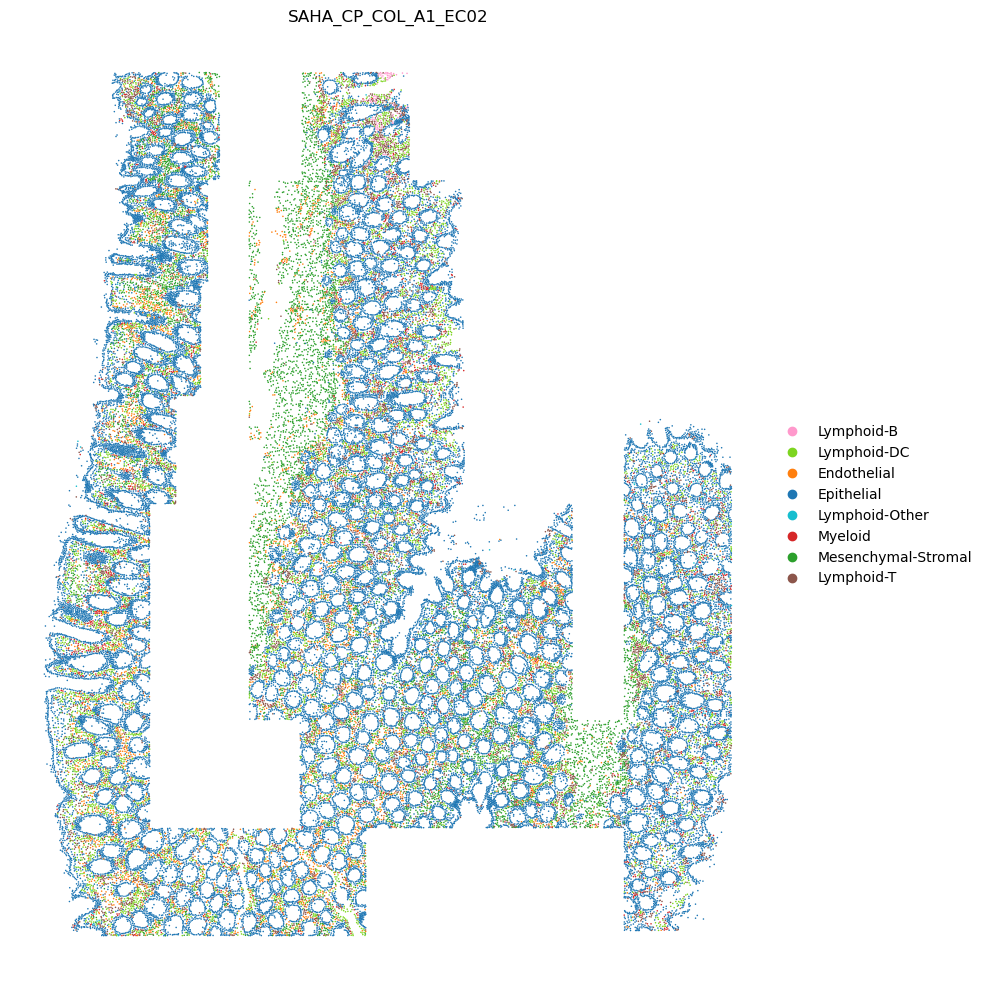

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


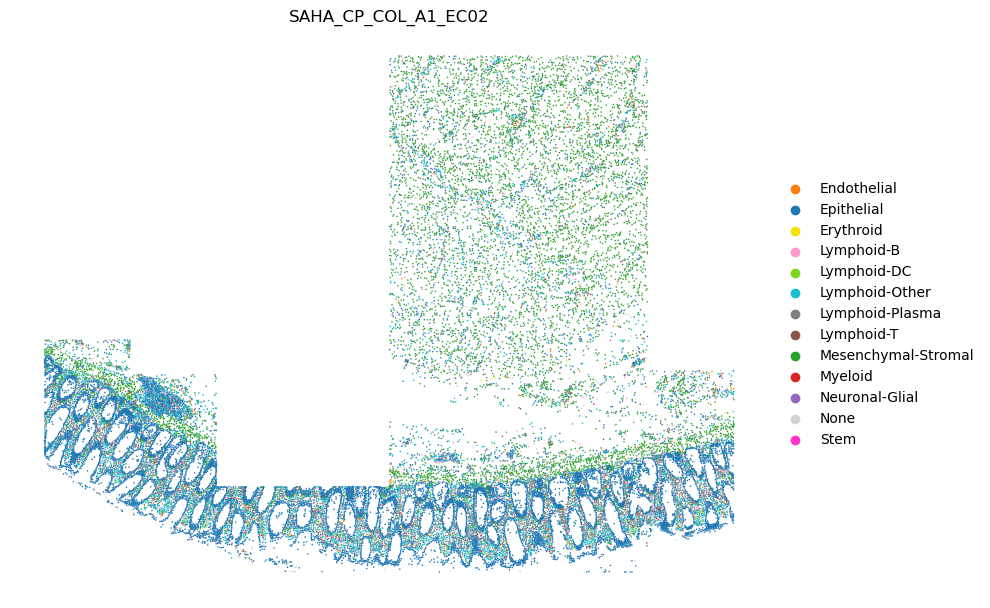

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


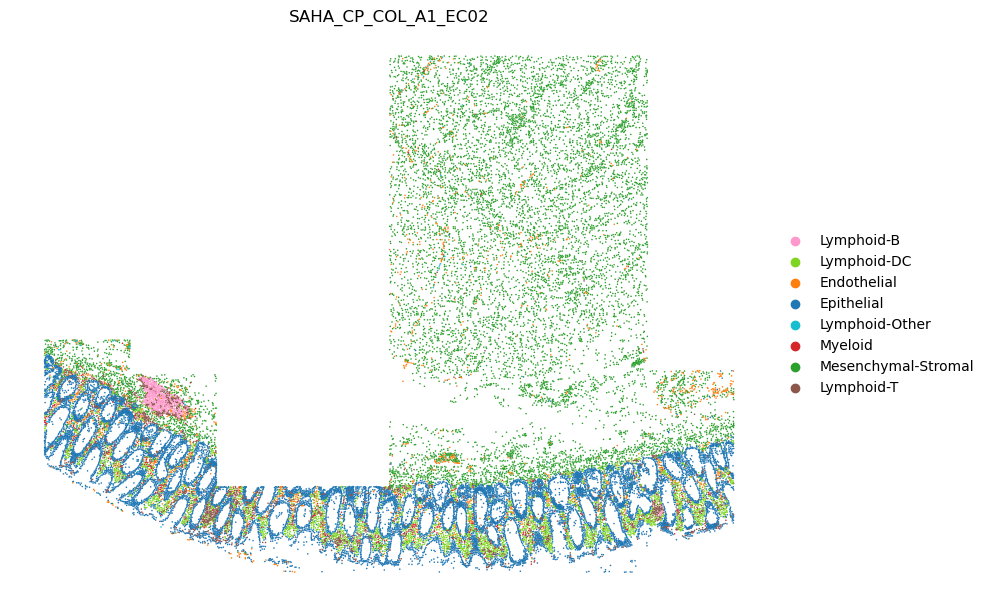

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


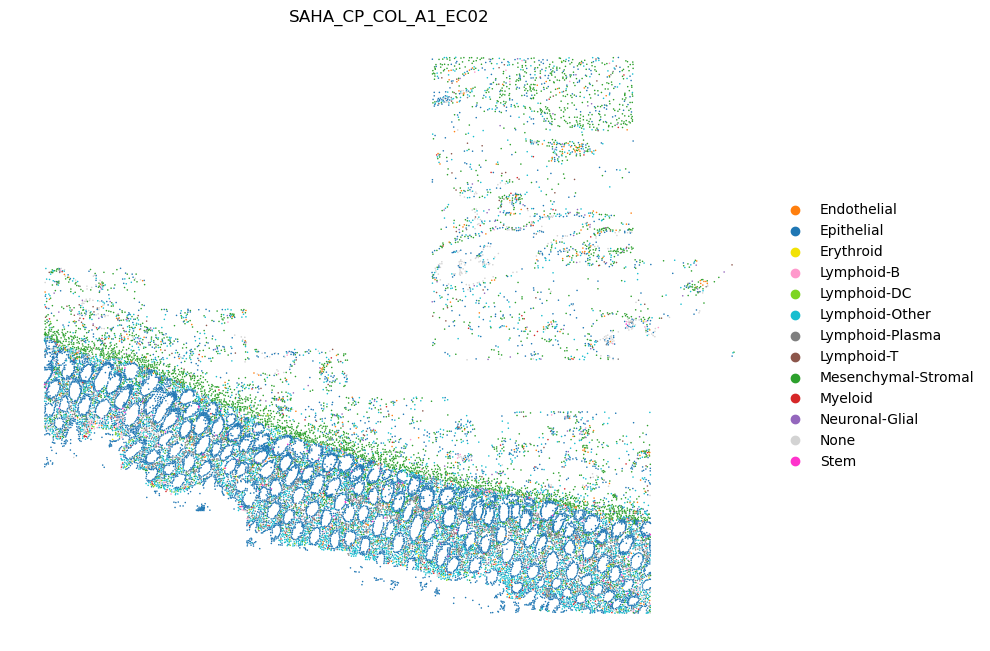

/mnt/scratch1/miniconda3/envs/rsc-luke/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


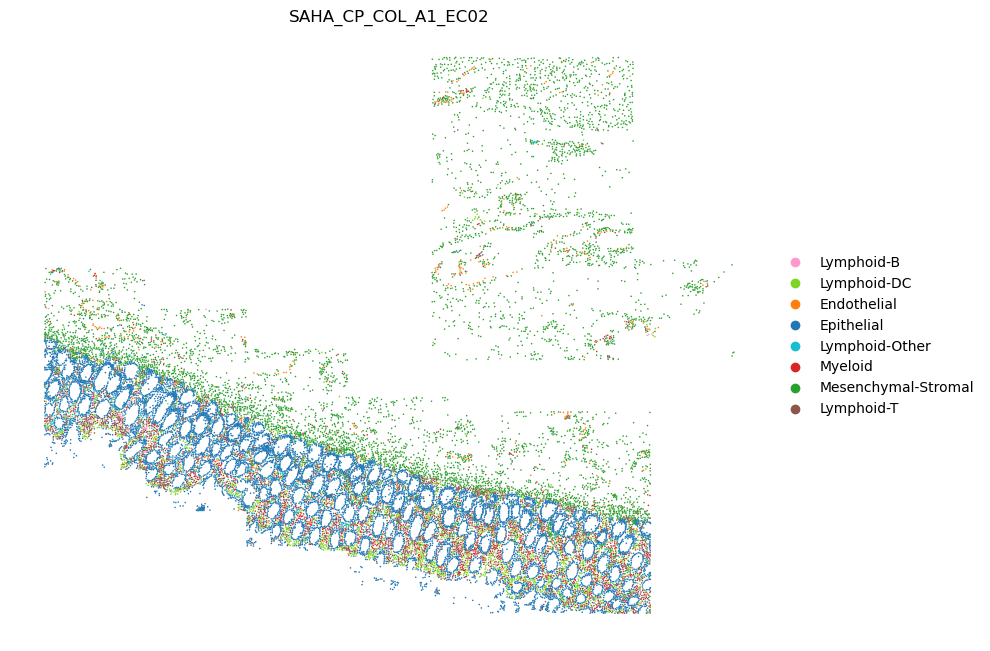

In [7]:
size=5

fovs_PRT1 = [42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59]
fovs_PRT2 = [79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109]
fovs_PRT3 = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26]
fovs_PRT4 = [72,73,74,75,76,77,78,71,60,61,63,69,62,64,65,66,67,68,70]

fovs = [fovs_PRT1,fovs_PRT2,fovs_PRT3,fovs_PRT4]

PRT.obs['fov_int'] = pd.to_numeric(PRT.obs['fov'], errors='coerce')

palette_PRT = ['#ff7f0e', #endo
           '#1f77b4', #epi
           '#f2e205', #ery
           '#ff99cc', #B
           '#7DD520', #DC
           '#17becf', #Other
           '#7f7f7f', #Plasma
           '#8c564b', #T
           '#2ca02c', #Mesen
           '#d62728', #Myeloid
           '#9467bd', #Neuro
           'lightgray', #None
           '#ff33cc', #Stem
]

'''palette_PRTSM = [
    '#ff99cc', #b
    '#ac402a', #cd4 t
    '#C78072', #cd8 cyto
    '#6c4139', #cd8 t
    '#c2d3b0', #den
    # '#96453F', #eff mem t
    '#ff7f0e', #endo
    '#1f77b4', #epi
    '#96453F', #exhaust
    '#8FCE00', #fibro
    '#17becf', #imm    
    '#CDABAB', #m1
    '#D87272', #m2
    '#c42829', #macro
    '#CD84D8', #mono
    '#d62728', #mye
    '#ffd966', #nk
    '#D7546F', #naive t
    '#B54141', #neutro
    '#7f7f7f', #plasma
    '#2ca02c', #stroma
    '#8c564b', #t
    '#9A2912', #tfh
    '#A6786A', #treg
    '#689933', #pDC
]

palette_PRTbroad = ['#ff7f0e', #endo
           '#1f77b4', #epi
           '#ff99cc', #B
           '#7DD520', #DC
           '#17becf', #Other
           '#7f7f7f', #Plasma
           '#8c564b', #T
           '#2ca02c', #Mesen
           '#d62728', #Myeloid
]'''

palette_PRTSM = [
    '#ff99cc', #b
    '#c2d3b0', #den
    '#ff7f0e', #endo
    '#1f77b4', #epi
    '#17becf', #imm    
    '#d62728', #mye
    '#2ca02c', #stroma
    '#8c564b', #t
]

palette_PRTbroad = [
    '#ff99cc', #B
    '#7DD520', #DC
    '#ff7f0e', #endo
    '#1f77b4', #epi  
    '#17becf', #Other
    '#d62728', #Myeloid
    '#2ca02c', #Mesen
    '#8c564b', #T
]

for fov in fovs:
    # plot MaxFuse
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    sc.pl.embedding(PRT[PRT.obs['fov_int'].isin(fov)], "spatial", color='celltype_mf', ax=ax, s=size, show=False, palette=palette_PRT)

    # Customize the plot
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_aspect('equal')
    ax.set_facecolor('white')
    ax.set_title(PRT_name)

    # Remove the spines (borders)
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.show()

    # plot SCIMAP
    '''fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    sc.pl.embedding(PRT[PRT.obs['fov_int'].isin(fov)], "spatial", color='phenotype', ax=ax, s=size, show=False, palette=palette_PRTSM)

    # Customize the plot
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_aspect('equal')
    ax.set_facecolor('white')
    ax.set_title(PRT_name)

    # Remove the spines (borders)
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.show()'''

    # plot SCIMAP broad
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    sc.pl.embedding(PRT[PRT.obs['fov_int'].isin(fov)], "spatial", color='phenotype_broad', ax=ax, s=size, show=False, palette=palette_PRTbroad)

    # Customize the plot
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_aspect('equal')
    ax.set_facecolor('white')
    ax.set_title(PRT_name)

    # Remove the spines (borders)
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.show()

In [9]:
print(PRT_ALL)

AnnData object with n_obs × n_vars = 3548712 × 64
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'nCount_RNA', 'nFeature_RNA', 'nCount_negprobes', 'nFeature_negprobes', 'Area.um2', 'cell', 'SAHA_name', 'SAHA_organcode', 'SAHA_batchcode', 'Mean.CD68', 'Max.CD68', 'cellSegmentationSetId', 'cellSegmentationSetName', 'batch', 'n_counts', 'n_genes', 'nn__cluster_cluster_', 'area.qc', 'mean.neg', 'negprobe.qc', 'n_high_quant', 'high.express.qc', 'n_low_quant', 'low.express.qc', 'remove_flagged_cells', 'c_round_1', 'c_round_2', 'c_round_3', 'c_cell_type_number', 'c_final_cell_type', 'RNA_spatialclust__neighbours_1', 'RNA_s